<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# Procesamiento de lenguaje natural
## Desafío 4: Traductor Seq2Seq (inglés → español)

Nombre(s):
* Santiago Bettig

## **Consigna del Desafío 4**

* Replicar el modelo traductor desarrollado en clase y extender su entrenamiento utilizando un conjunto de datos más amplio y secuencias de mayor longitud.
* Modificar valores de hiperparámetros (por ejemplo, el número de unidades en las capas LSTM) y analizar su impacto en el desempeño del traductor.
* Analizar el impacto del número de neuronas en las capas recurrentes, comparando el desempeño de distintas configuraciones del modelo.
* Generar y presentar al menos cinco ejemplos de traducciones producidas por el modelo entrenado.
* Interpretar a detalle los resultados obtenidos, considerando métricas de evaluación, calidad de las traducciones y posibles limitaciones del enfoque utilizado.

### Actividad opcional elegida
* Experimentar con diferentes estrategias de generación de secuencias, como muestreo aleatorio (sampling) o búsqueda por haz (beam search).

## **Resolución del Desafío 4**

Parto del notebook `Traductor.ipynb` visto en clase: un modelo *encoder-decoder* (Seq2Seq) con LSTM, donde el encoder lee la oración en inglés y resume su contenido en los estados `(h, c)` de la LSTM, y el decoder genera la oración en español palabra por palabra arrancando desde esos estados (con *teacher forcing* durante el entrenamiento).

Lo replico manteniendo la arquitectura, pero con algunas mejoras que voy justificando a medida que aparecen (función de pérdida *sparse*, enmascarado del padding y BLEU como métrica de traducción).

**Sobre la ejecución:** desarrollé y verifiqué el notebook localmente en CPU con una versión reducida del experimento (`QUICK_RUN = True`: menos oraciones y épocas). Los entrenamientos completos (`QUICK_RUN = False`) los ejecuté en Google Colab con GPU (T4), donde entrenar es aproximadamente un orden de magnitud más rápido. Cada modelo guarda sus pesos y su historial en disco, por lo que la versión final del notebook la ejecuté localmente cargando los modelos ya entrenados en Colab. Por eso los tiempos por época que aparecen en las tablas corresponden a la GPU de Colab.

Primero importo las librerías que voy a necesitar a lo largo de todo el notebook y fijo la semilla para que los resultados sean reproducibles.

In [1]:
import os
import re
import time
import hashlib
import pickle
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from collections import defaultdict
from tensorflow.keras.preprocessing.text import Tokenizer, text_to_word_sequence
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Input, LSTM, Dense, Embedding, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping, Callback
from nltk.translate.bleu_score import corpus_bleu, sentence_bleu, SmoothingFunction

# Fijo una semilla para que el shuffle del dataset, la separación train/val y el entrenamiento sean reproducibles
SEED = 40
np.random.seed(SEED)
tf.random.set_seed(SEED)

# En GPU, TensorFlow reserva por defecto casi toda la memoria de la placa al iniciar.
# Activo el crecimiento gradual para que solo ocupe la memoria que realmente necesita.
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)

print("TensorFlow:", tf.__version__)
print("Dispositivos:", [d.device_type for d in tf.config.list_physical_devices()])

TensorFlow: 2.21.0
Dispositivos: ['CPU']


### 1 - Datos

Uso el mismo dataset que en clase: el corpus de pares de oraciones inglés-español del proyecto [Tatoeba](https://tatoeba.org/) / [ManyThings](http://www.manythings.org/anki/), que distribuye TensorFlow. Cada línea del archivo tiene la oración en inglés y su traducción al español separadas por un tabulador.

A diferencia del notebook de clase (que usa `os.system("curl ...")` y `unzip`, comandos que no siempre están disponibles en Windows), descargo y descomprimo con `urllib` y `zipfile` de la librería estándar. Además leo el archivo explícitamente en `utf-8`, porque si no en Windows se lee con la codificación por defecto del sistema y se rompen los acentos y la `ñ`.

In [2]:
DATA_DIR = 'spa-eng'
DATA_URL = 'http://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip'

if not os.path.exists(DATA_DIR):
    urllib.request.urlretrieve(DATA_URL, 'spa-eng.zip')
    with zipfile.ZipFile('spa-eng.zip') as z:
        z.extractall('.')
    os.remove('spa-eng.zip')
    print("Dataset descargado y descomprimido.")
else:
    print("El dataset ya se encuentra descargado.")

with open(os.path.join(DATA_DIR, 'spa.txt'), encoding='utf-8') as f:
    lines = f.read().split('\n')[:-1]

print(f"Cantidad de pares en el corpus: {len(lines)}")
print("\nAlgunas líneas de ejemplo:")
for l in lines[:3] + lines[-3:]:
    print("  ", l)

El dataset ya se encuentra descargado.
Cantidad de pares en el corpus: 118964

Algunas líneas de ejemplo:
   Go.	Ve.
   Go.	Vete.
   Go.	Vaya.
   A carbon footprint is the amount of carbon dioxide pollution that we produce as a result of our activities. Some people try to reduce their carbon footprint because they are concerned about climate change.	Una huella de carbono es la cantidad de contaminación de dióxido de carbono que producimos como producto de nuestras actividades. Algunas personas intentan reducir su huella de carbono porque están preocupados acerca del cambio climático.
   Since there are usually multiple websites on any given topic, I usually just click the back button when I arrive on any webpage that has pop-up advertising. I just go to the next page found by Google and hope for something less irritating.	Como suele haber varias páginas web sobre cualquier tema, normalmente sólo le doy al botón de retroceso cuando entro en una página web que tiene anuncios en ventanas 

Las líneas vienen ordenadas por longitud (de las oraciones más cortas a las más largas). Por eso en clase se mezclan antes de quedarse con las primeras `MAX_NUM_SENTENCES`: si no, el modelo solo vería frases de una o dos palabras.

Antes de decidir cuántas oraciones usar y qué longitud máxima permitir, analizo la distribución de longitudes (en palabras) del corpus completo.

              en         es
count  118964.00  118964.00
mean        6.31       6.08
std         2.61       2.76
min         1.00       1.00
50%         6.00       6.00
90%        10.00      10.00
95%        11.00      11.00
99%        14.00      15.00
max        47.00      49.00


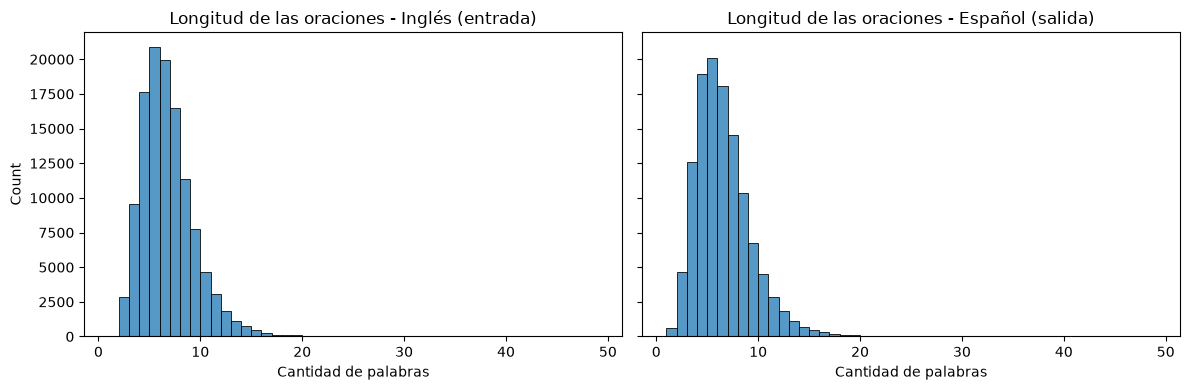

In [3]:
pairs = [l.split('\t')[:2] for l in lines if '\t' in l]
df_len = pd.DataFrame({
    'en': [len(en.split()) for en, _ in pairs],
    'es': [len(es.split()) for _, es in pairs],
})

print(df_len.describe(percentiles=[.5, .9, .95, .99]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, col, title in zip(axes, ['en', 'es'], ['Inglés (entrada)', 'Español (salida)']):
    sns.histplot(df_len[col], bins=range(1, 50), ax=ax)
    ax.set_title(f'Longitud de las oraciones - {title}')
    ax.set_xlabel('Cantidad de palabras')
plt.tight_layout()
plt.show()

In [4]:
# ¿Qué porcentaje de los pares entra completo para distintas longitudes máximas?
for max_len in [8, 10, 12, 15, 20, 25]:
    pct = ((df_len['en'] <= max_len) & (df_len['es'] <= max_len)).mean() * 100
    print(f"Pares con ambas oraciones <= {max_len:2d} palabras: {pct:5.1f}%")

Pares con ambas oraciones <=  8 palabras:  78.7%
Pares con ambas oraciones <= 10 palabras:  91.2%
Pares con ambas oraciones <= 12 palabras:  96.5%
Pares con ambas oraciones <= 15 palabras:  99.1%
Pares con ambas oraciones <= 20 palabras:  99.9%
Pares con ambas oraciones <= 25 palabras: 100.0%


### 2 - Preprocesamiento

De la exploración anterior saco dos conclusiones:

* El modelo de clase usaba `max_input_len = 20` y `max_out_len = 22`, que ya cubren el 99,9% del corpus. Lo que realmente lo limitaba era usar **solo 10.000 oraciones** (menos del 10% del corpus): en una muestra así casi no aparecen frases largas (las de más de 15 palabras son menos del 1%), por lo que el modelo prácticamente no aprende a traducirlas. Por eso, para el **modelo extendido** uso el corpus completo y subo la longitud máxima a 25 palabras, de modo de no descartar ni truncar ninguna oración relevante.
* Para el **modelo base** mantengo exactamente la configuración de clase (10.000 oraciones, longitudes 20/22, vocabulario de 8.000 palabras), así tengo una referencia contra la cual comparar.

Defino entonces las dos configuraciones de datos. Con `QUICK_RUN = True` el modelo extendido usa un subconjunto de 20.000 oraciones para poder verificar rápido el notebook en CPU.

In [5]:
QUICK_RUN = False   # True: verificación rápida en CPU | False: corrida completa (Colab con GPU)

DATA_CONFIGS = {
    # Réplica de la configuración de clase
    'base':      dict(n_sentences=10_000, max_input_len=20, max_out_len=22, vocab_in=8_000,  vocab_out=8_000),
    # Más datos y secuencias más largas (None = corpus completo)
    'extendido': dict(n_sentences=20_000 if QUICK_RUN else None,
                      max_input_len=25, max_out_len=26, vocab_in=10_000, vocab_out=10_000),
}

**Tamaño de vocabulario del modelo extendido.** Con el corpus completo hay ~13.500 palabras distintas en inglés y ~26.000 en español (el español tiene mucha más flexión: conjugaciones, género y número). Medí qué porcentaje de las apariciones de palabras cubre cada tamaño de vocabulario:

| Vocabulario | 5.000 | 8.000 | 10.000 | 15.000 | 20.000 |
|---|---|---|---|---|---|
| Cobertura inglés | 97,8% | 99,1% | 99,5% | 100% | 100% |
| Cobertura español | 93,4% | 95,9% | 96,9% | 98,4% | 99,2% |

Elijo **10.000 palabras** para ambos idiomas: cubre el 99,5% del inglés y el 96,9% del español. Agrandar el vocabulario de salida tiene un costo alto, porque la capa `Dense` final con softmax tiene que calcular una probabilidad para *cada* palabra del vocabulario en *cada* paso del decoder, y es la parte más cara del modelo.

**Separación train / validación / test.** El corpus tiene muchas oraciones en inglés repetidas con varias traducciones válidas (por ejemplo *"Go."* → *"Ve."*, *"Vete."*, *"Vaya."*): hay ~103.000 oraciones en inglés distintas para ~119.000 pares. Si separara los pares al azar, la misma oración en inglés podría quedar en train y en test, y el modelo sería evaluado sobre frases que ya vio. Por eso separo **por oración de origen** (~80% / 10% / 10%): todas las traducciones de una misma oración en inglés caen en el mismo conjunto. Como ventaja adicional, en test puedo usar todas las traducciones de referencia al calcular BLEU.

Asigno el conjunto de cada oración con un **hash determinístico de su texto** en lugar de un shuffle. Así, una oración cae siempre en el mismo conjunto, sin importar si trabajo con 10.000 oraciones o con el corpus completo. Como las oraciones del modelo base son un subconjunto de las del extendido (misma permutación), el train del base queda contenido en el del extendido, y lo mismo ocurre con validación y test. Esto me permite **comparar ambos modelos sobre el mismo conjunto de test** sin que ninguno haya visto esas oraciones durante el entrenamiento.

In [6]:
def load_pairs(lines, n_sentences=None, seed=SEED):
    # Mezclo los pares (vienen ordenados por longitud) y me quedo con los primeros n_sentences
    pairs = [l.rstrip().split('\t')[:2] for l in lines if '\t' in l]
    idx = np.random.default_rng(seed).permutation(len(pairs))[:n_sentences]
    return [pairs[i] for i in idx]


def split_of(sentence, val_pct=10, test_pct=10):
    # Asigno el conjunto con un hash determinístico de la oración en inglés: la misma oración
    # cae siempre en el mismo conjunto, sin importar con qué subconjunto del corpus trabaje
    bucket = int(hashlib.md5(sentence.encode('utf-8')).hexdigest(), 16) % 100
    return 'val' if bucket < val_pct else 'test' if bucket < val_pct + test_pct else 'train'


def split_by_source(pairs):
    splits = {'train': [], 'val': [], 'test': []}
    for en, es in pairs:
        splits[split_of(en)].append((en, es))
    return splits

**Tokenización.** Uso el `Tokenizer` de Keras igual que en clase (pasa a minúsculas y elimina la puntuación), con cuatro cambios:

1. **Ajusto los tokenizers solo con el conjunto de train**, para que validación y test simulen oraciones nunca vistas.
2. **Agrego un token `<unk>`** (`oov_token`). Sin él, el `Tokenizer` *elimina en silencio* las palabras que quedan fuera del vocabulario, y la oración pierde palabras sin que el modelo se entere.
3. **Corrijo cómo se incorpora `<sos>` al vocabulario.** En clase se hacía `fit_on_texts(["<sos>", "<eos>"] + output_sentences)`. `<eos>` aparece en todas las oraciones y queda con un índice bajo, pero `<sos>` aparece una sola vez y queda **al final del vocabulario** (índice 3434 en la salida de clase). Con 10.000 oraciones funcionaba porque el vocabulario completo (7.803) entraba en `num_words = 8000`. Pero con el corpus completo (26.000 palabras en español) `<sos>` quedaría fuera del límite y `texts_to_sequences` lo descartaría: **el decoder nunca recibiría el token de inicio**. Para evitarlo, ajusto el tokenizer sobre las oraciones con `<sos>` y `<eos>` ya agregados, así ambos tokens quedan entre los más frecuentes.

4. **Expando las contracciones del inglés** antes de tokenizar (*don't* → *do not*, *i'm* → *i am*, *tom's* → *tom 's*). Lo detecté al construir la matriz de embeddings de la sección 3: las palabras del vocabulario que no tenían vector GloVe eran casi todas contracciones (*don't*, *i'm*, *it's*, *can't*…), que están entre las más frecuentes del corpus (*don't* sola aparece ~5.000 veces). Como el embedding del encoder está congelado, todas recibían el mismo vector nulo y el modelo **no podía distinguir *don't* de *it's***; entre otras cosas se perdía la negación. GloVe Twitter sí tiene *not*, *am*, *will*, *have* y *'s*, así que al separarlas todas quedan representadas. Como beneficio extra, el vocabulario se achica (*don't*, *doesn't* y *didn't* pasan a compartir *not*).

   Algunas expansiones son ambiguas (*'d* puede ser *would* o *had*; *'s* puede ser *is*, *has* o posesivo). En esos casos elijo la opción más frecuente, o dejo *'s* como token propio, que también existe en GloVe.

En el tokenizer de salida, igual que en clase, saco `<` y `>` de los filtros (para no romper `<sos>`/`<eos>`) y agrego `¿`. También agrego `¡`, que en clase no se filtraba y generaba tokens distintos para *"¡hola"* y *"hola"*.

**Padding y largo máximo.** A diferencia de clase:
* En lugar de truncar las oraciones que superan el largo máximo, las **descarto**. `pad_sequences` trunca por defecto desde el *principio* (`truncating='pre'`), así que en una oración de salida demasiado larga se perdería justamente el `<sos>`. Con los largos elegidos se descarta menos del 0,1% de los pares.
* Uso padding al **final** (`'post'`) también en el encoder. Como más adelante enmascaro el padding (`mask_zero=True`), la LSTM ignora esas posiciones y da igual dónde estén. El padding al final es además el formato que admite la implementación optimizada de LSTM para GPU (cuDNN) cuando hay máscara.

In [7]:
OUTPUT_FILTERS = '!"#$%&()*+,-./:;=¿¡?@[\\]^_`{|}~\t\n'   # sin '<' ni '>' para conservar <sos>/<eos>

# Expansión de contracciones del inglés (el orden importa: primero los casos irregulares)
CONTRACTIONS = [
    (r"\bwon't\b", "will not"), (r"\bcan't\b", "can not"), (r"\bshan't\b", "shall not"),
    (r"n't\b", " not"), (r"'m\b", " am"), (r"'re\b", " are"), (r"'ve\b", " have"),
    (r"'ll\b", " will"), (r"'d\b", " would"), (r"'s\b", " 's"),
]


def normalize_en(text):
    text = text.lower().replace('’', "'")   # unifico el apóstrofo tipográfico (’) con el recto (')
    for pattern, replacement in CONTRACTIONS:
        text = re.sub(pattern, replacement, text)
    return text


for s in ["I don't think Tom's coming.", "We can't, but they won't either.", "I'd say you're right."]:
    print(f"{s:35s} -> {normalize_en(s)}")

I don't think Tom's coming.         -> i do not think tom 's coming.
We can't, but they won't either.    -> we can not, but they will not either.
I'd say you're right.               -> i would say you are right.


In [8]:
def prepare_data(n_sentences, max_input_len, max_out_len, vocab_in, vocab_out):
    splits = split_by_source(load_pairs(lines, n_sentences))
    train_en = [normalize_en(en) for en, _ in splits['train']]
    train_es = ['<sos> ' + es + ' <eos>' for _, es in splits['train']]

    input_tokenizer = Tokenizer(num_words=vocab_in, oov_token='<unk>')
    input_tokenizer.fit_on_texts(train_en)
    output_tokenizer = Tokenizer(num_words=vocab_out, oov_token='<unk>', filters=OUTPUT_FILTERS)
    output_tokenizer.fit_on_texts(train_es)

    data = dict(input_tokenizer=input_tokenizer, output_tokenizer=output_tokenizer,
                max_input_len=max_input_len, max_out_len=max_out_len,
                num_words_input=min(len(input_tokenizer.word_index) + 1, vocab_in),
                num_words_output=min(len(output_tokenizer.word_index) + 1, vocab_out))

    for name, split in splits.items():
        en = [p[0] for p in split]
        es = [p[1] for p in split]
        enc     = input_tokenizer.texts_to_sequences([normalize_en(s) for s in en])
        dec_in  = output_tokenizer.texts_to_sequences(['<sos> ' + s for s in es])
        dec_out = output_tokenizer.texts_to_sequences([s + ' <eos>' for s in es])

        # Descarto los pares que no entran en el largo máximo (en vez de truncarlos)
        keep = [i for i in range(len(split))
                if 0 < len(enc[i]) <= max_input_len and len(dec_out[i]) <= max_out_len]

        data[name] = dict(
            en=[en[i] for i in keep],
            es=[es[i] for i in keep],
            encoder_input=pad_sequences([enc[i] for i in keep],     maxlen=max_input_len, padding='post'),
            decoder_input=pad_sequences([dec_in[i] for i in keep],  maxlen=max_out_len,   padding='post'),
            decoder_output=pad_sequences([dec_out[i] for i in keep], maxlen=max_out_len,  padding='post'),
            n_dropped=len(split) - len(keep),
        )
    return data


datasets = {name: prepare_data(**cfg) for name, cfg in DATA_CONFIGS.items()}

for name, d in datasets.items():
    print(f"=== {name} ===")
    # num_words_* es el tamaño de las capas de embedding / softmax: vocabulario recortado + el índice 0 del padding
    print(f"  Vocabulario EN: {len(d['input_tokenizer'].word_index):6d} palabras -> num_words_input:  {d['num_words_input']}")
    print(f"  Vocabulario ES: {len(d['output_tokenizer'].word_index):6d} palabras -> num_words_output: {d['num_words_output']}")
    for split in ['train', 'val', 'test']:
        print(f"  {split:5s}: {len(d[split]['en']):6d} pares  (descartados por largo: {d[split]['n_dropped']})")

=== base ===
  Vocabulario EN:   4440 palabras -> num_words_input:  4441
  Vocabulario ES:   6909 palabras -> num_words_output: 6910
  train:   7969 pares  (descartados por largo: 7)
  val  :    982 pares  (descartados por largo: 0)
  test :   1041 pares  (descartados por largo: 1)
=== extendido ===
  Vocabulario EN:  12186 palabras -> num_words_input:  10000
  Vocabulario ES:  23582 palabras -> num_words_output: 10000
  train:  95353 pares  (descartados por largo: 40)
  val  :  11687 pares  (descartados por largo: 3)
  test :  11878 pares  (descartados por largo: 3)


Verifico que no haya filtraciones: ninguna oración en inglés de entrenamiento (de ninguno de los dos modelos) aparece en los conjuntos de validación o test.

In [9]:
train_src = {en for d in datasets.values() for en in d['train']['en']}
for split in ['val', 'test']:
    eval_src = {en for d in datasets.values() for en in d[split]['en']}
    print(f"Oraciones de train que aparecen en {split}: {len(train_src & eval_src)}")

base_test, ext_test = set(datasets['base']['test']['en']), set(datasets['extendido']['test']['en'])
print(f"Test del base contenido en el test del extendido: {base_test <= ext_test}")

Oraciones de train que aparecen en val: 0
Oraciones de train que aparecen en test: 0
Test del base contenido en el test del extendido: True


Verifico que los tokens especiales hayan quedado con índices bajos (dentro del vocabulario) y miro cómo queda codificado un ejemplo:

In [10]:
d = datasets['extendido']
w2i_out = d['output_tokenizer'].word_index
print("Índices -> <unk>:", w2i_out['<unk>'], "| <sos>:", w2i_out['<sos>'], "| <eos>:", w2i_out['<eos>'])

i = 0
print("\nEN:", d['train']['en'][i])
print("ES:", d['train']['es'][i])
print("encoder_input :", d['train']['encoder_input'][i])
print("decoder_input :", d['train']['decoder_input'][i])
print("decoder_output:", d['train']['decoder_output'][i])

Índices -> <unk>: 1 | <sos>: 2 | <eos>: 3

EN: Come here before seven o'clock.
ES: Ven aquí antes de las siete.
encoder_input : [ 73  56 149 677 548   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0]
decoder_input : [  2 516  49 133   4  31 668   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0]
decoder_output: [516  49 133   4  31 668   3   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0]


Se ve el desplazamiento de *teacher forcing*: la entrada del decoder empieza con `<sos>` y la salida esperada es la misma secuencia corrida un lugar a la izquierda y terminada en `<eos>`. En cada paso el decoder recibe la palabra correcta anterior y tiene que predecir la siguiente.

Por último, mido la tasa de palabras desconocidas (`<unk>`) en validación, que indica qué tan bien el vocabulario de train cubre oraciones nuevas:

In [11]:
def unk_rate(seqs, unk_idx=1):
    tokens = seqs[seqs > 0]
    return (tokens == unk_idx).mean() * 100

for name, d in datasets.items():
    print(f"{name:10s} -> <unk> en val: entrada {unk_rate(d['val']['encoder_input']):.2f}% | "
          f"salida {unk_rate(d['val']['decoder_output']):.2f}%")

base       -> <unk> en val: entrada 3.62% | salida 6.75%
extendido  -> <unk> en val: entrada 1.08% | salida 3.59%


Más datos de entrenamiento reducen la proporción de palabras desconocidas en oraciones nuevas, sobre todo en español, donde el vocabulario es más disperso. Este es un primer beneficio concreto de extender el dataset: en validación, el modelo base (entrenado con 8.000 pares) se encuentra con una palabra de salida que nunca vio aproximadamente 1 de cada 15 veces (6,8%), mientras que con el corpus completo la proporción se reduce a casi la mitad (3,6%).

### 3 - Embeddings preentrenados (GloVe) para el encoder

Igual que en clase, inicializo la capa de embedding del encoder con vectores **GloVe** preentrenados y la dejo congelada (`trainable=False`). El archivo que provee la cátedra corresponde a **GloVe Twitter de 50 dimensiones** (~1,2 millones de palabras, entrenado sobre tweets en inglés). Así el encoder arranca con una noción de similitud semántica entre palabras (por ejemplo, *car* y *auto* quedan cerca) que con unas decenas de miles de oraciones sería difícil de aprender desde cero.

El decoder (español) no tiene embeddings preentrenados: en clase su embedding se aprende durante el entrenamiento, y mantengo ese esquema.

Descargo el archivo desde Google Drive con `gdown`, como en el notebook de clase, verificando que lo descargado no sea una página HTML de error de Drive en lugar del pickle.

In [12]:
GLOVE_PATH    = 'gloveembedding.pkl'
GLOVE_FILE_ID = '1KY6avD5I1eI2dxQzMkR3WExwKwRq2g94'


def _is_valid_pickle(path):
    with open(path, 'rb') as f:
        head = f.read(20).lower()
    return b'<html' not in head and b'<!doctype' not in head


if not os.path.exists(GLOVE_PATH) or not _is_valid_pickle(GLOVE_PATH):
    import gdown
    gdown.download(id=GLOVE_FILE_ID, output=GLOVE_PATH, quiet=False)
    if not _is_valid_pickle(GLOVE_PATH):
        raise ValueError("El archivo descargado no es un pickle válido.")
    print("Descarga completada.")
else:
    print("gloveembedding.pkl ya disponible.")

with open(GLOVE_PATH, 'rb') as f:
    glove = pickle.load(f)   # array estructurado con campos 'word' y 'embedding'

glove_word2idx = {w: i for i, w in enumerate(glove['word'])}
EMBED_DIM = glove['embedding'].shape[1]
print(f"GloVe: {len(glove_word2idx)} palabras de dimensión {EMBED_DIM}")

gloveembedding.pkl ya disponible.


GloVe: 1193433 palabras de dimensión 50


Armo la matriz de embeddings para cada configuración: la fila `i` es el vector GloVe de la palabra con índice `i` en el tokenizer de entrada. Las filas del padding (índice 0), de `<unk>` y de las palabras que no están en GloVe quedan en cero.

Uso `num_words_input` (vocabulario + 1) como cantidad de filas. En clase se usaba `nb_words = min(MAX_VOCAB_SIZE, len(word2idx_inputs))`, que con un vocabulario más chico que el límite deja **una fila menos de la necesaria**: la palabra con el índice más alto queda fuera de la matriz. En GPU eso pasa inadvertido (TensorFlow devuelve ceros para índices fuera de rango), pero en CPU produce un error.

In [13]:
def build_embedding_matrix(word_index, num_words, glove, glove_word2idx):
    matrix = np.zeros((num_words, glove['embedding'].shape[1]), dtype=np.float32)
    for word, i in word_index.items():
        if 1 < i < num_words and word in glove_word2idx:   # el padding (0) y <unk> (1) quedan en cero
            matrix[i] = glove['embedding'][glove_word2idx[word]]
    return matrix


for name, d in datasets.items():
    d['embedding_matrix'] = build_embedding_matrix(
        d['input_tokenizer'].word_index, d['num_words_input'], glove, glove_word2idx
    )
    words = d['embedding_matrix'][2:]          # descarto las filas de padding (0) y <unk> (1)
    n_null = (np.abs(words).sum(axis=1) == 0).sum()
    print(f"{name:10s} -> matriz {d['embedding_matrix'].shape} | palabras sin vector GloVe: "
          f"{n_null} de {len(words)} ({n_null / len(words) * 100:.1f}%)")

base       -> matriz (4441, 50) | palabras sin vector GloVe: 72 de 4439 (1.6%)
extendido  -> matriz (10000, 50) | palabras sin vector GloVe: 258 de 9998 (2.6%)


Miro qué palabras del vocabulario siguen sin vector GloVe después de expandir las contracciones (ordenadas por frecuencia):

In [14]:
d = datasets['extendido']
missing = [w for w, i in d['input_tokenizer'].word_index.items()
           if 1 < i < d['num_words_input'] and w not in glove_word2idx]
print(missing[:40])

# Ya armé las matrices de embeddings: libero GloVe (~1,2 millones de palabras) de la memoria
del glove, glove_word2idx

['30', '2', '10', '000', '00', '5', '100', '3', '6', '20', '1', '7', '8', '500', '50', '4', '9', '2013', '40', '300', '24', '200', '54', '11', '25', '18', '400', '1939', '10th', '15', '150', "parents'", 'telephoned', '17', '20th', '65', '80', '13', "minutes'", '60']


Al expandir las contracciones desaparecen de esta lista las palabras más frecuentes del corpus, y las que quedan sin vector (alrededor del 2-3% del vocabulario) tienen poco peso:

* **Números**: GloVe Twitter no tiene vectores para números concretos, porque en su preprocesamiento los reemplaza a todos por un token genérico `<number>`. Esto es una **limitación** del enfoque: como el embedding del encoder está congelado, el modelo ve todos los números como el mismo vector nulo y no puede distinguir *"Tom tiene 30 años"* de *"Tom tiene 20 años"*. Un traductor real resolvería esto con un mecanismo de copia o de atención, o con tokenización por subpalabras.
* **Palabras raras o mal separadas**: formas poco frecuentes (*telephoned*, *10th*) y posesivos plurales (*parents'*, *minutes'*), cuyo apóstrofo final no cubren las reglas de expansión. Aparecen pocas veces en el corpus y tienen poco impacto.

### 4 - Modelo Seq2Seq base (réplica de clase)

#### 4.1 - Arquitectura

Mantengo la arquitectura de clase:

* **Encoder**: `Embedding` GloVe congelado (50 dimensiones) → `Dropout(0.3)` → `LSTM(n_units)`, del que solo me quedo con los estados finales `(h, c)`, que son el "resumen" de la oración en inglés.
* **Decoder**: `Embedding` entrenable (dimensión `n_units`) → `Dropout(0.3)` → `LSTM(n_units)` inicializada con los estados del encoder → `Dense(num_words_output, softmax)`, que en cada paso da la distribución de probabilidad de la siguiente palabra.

Cambio dos cosas en la forma de entrenar:

1. **`mask_zero=True` en ambos embeddings.** En clase el padding se trataba como una palabra más: la LSTM del encoder procesaba los ceros y, sobre todo, **la loss y el accuracy se calculaban también en las posiciones de padding**. Como la mayoría de las posiciones de la salida son padding (lo mido más abajo), el modelo puede obtener un accuracy alto con solo aprender a predecir "padding" después del `<eos>`, y la métrica queda inflada. Con la máscara, Keras ignora esas posiciones en la LSTM, en la loss y en el accuracy.
2. **`sparse_categorical_crossentropy`** en lugar de `categorical_crossentropy` con *one-hot*. Matemáticamente es la misma función de pérdida, pero recibe el índice de la palabra correcta en lugar de un vector one-hot. Con el vocabulario extendido, cada batch en one-hot ocuparía 64 × 26 × 10.000 floats (~67 MB), contra unos pocos KB con índices.

La función devuelve el modelo de entrenamiento y los dos modelos de inferencia (encoder y decoder paso a paso), que comparten las mismas capas y, por lo tanto, los mismos pesos.

In [15]:
def build_seq2seq(data, n_units, dropout=0.3):
    # ---------- Encoder ----------
    enc_inputs = Input(shape=(None,), name='encoder_inputs')
    enc_emb = Embedding(data['num_words_input'], EMBED_DIM, mask_zero=True, trainable=False,
                        embeddings_initializer=tf.keras.initializers.Constant(data['embedding_matrix']),
                        name='encoder_embedding')(enc_inputs)
    enc_emb = Dropout(dropout, name='encoder_dropout')(enc_emb)
    _, state_h, state_c = LSTM(n_units, return_state=True, name='encoder_lstm')(enc_emb)
    enc_states = [state_h, state_c]

    # ---------- Decoder ----------
    dec_inputs = Input(shape=(None,), name='decoder_inputs')
    dec_emb_layer   = Embedding(data['num_words_output'], n_units, mask_zero=True, name='decoder_embedding')
    dec_dropout     = Dropout(dropout, name='decoder_dropout')
    dec_lstm_layer  = LSTM(n_units, return_sequences=True, return_state=True, name='decoder_lstm')
    dec_dense_layer = Dense(data['num_words_output'], activation='softmax', name='decoder_dense')

    dec_out, _, _ = dec_lstm_layer(dec_dropout(dec_emb_layer(dec_inputs)), initial_state=enc_states)
    dec_out = dec_dense_layer(dec_out)

    model = Model([enc_inputs, dec_inputs], dec_out, name=f'seq2seq_{n_units}')

    # ---------- Modelos de inferencia (reutilizan las capas entrenadas) ----------
    encoder_model = Model(enc_inputs, enc_states, name='encoder_inference')

    dec_token_in = Input(shape=(1,), name='dec_token')
    dec_h_in     = Input(shape=(n_units,), name='dec_state_h')
    dec_c_in     = Input(shape=(n_units,), name='dec_state_c')
    out, h, c = dec_lstm_layer(dec_emb_layer(dec_token_in), initial_state=[dec_h_in, dec_c_in])
    decoder_model = Model([dec_token_in, dec_h_in, dec_c_in], [dec_dense_layer(out), h, c],
                          name='decoder_inference')

    return dict(model=model, encoder=encoder_model, decoder=decoder_model, n_units=n_units)


s2s_demo = build_seq2seq(datasets['base'], n_units=256)
s2s_demo['model'].summary()

Model: "seq2seq_256"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_inputs      │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_inputs      │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_embedding   │ (None, None, 50)  │    222,050 │ encoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_embedding   │ (None, 1, 256)    │  1,768,960 │ decoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dropout     │ (None, None, 50)  │          0 │ encoder_embeddin… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, None)      │          0 │ encoder_inputs[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dropout     │ (None, None, 256) │          0 │ decoder_embeddin… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 256),     │    314,368 │ encoder_dropout[… │
│                     │ (None, 256),      │            │ not_equal[0][0]   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, 1, 256),  │    525,312 │ decoder_dropout[… │
│                     │ (None, 256),      │            │ encoder_lstm[0][… │
│                     │ (None, 256)]      │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dense       │ (None, 1, 6910)   │  1,775,870 │ decoder_lstm[0][… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,606,560 (17.57 MB)

 Trainable params: 4,384,510 (16.73 MB)

 Non-trainable params: 222,050 (867.38 KB)

Como anticipé, la mayor parte de los parámetros entrenables está en la capa `Dense` de salida (`n_units × num_words_output`) y en el embedding del decoder, no en las LSTM.

Mido qué fracción de las posiciones de la salida es padding, para dimensionar cuánto inflaba el accuracy sin máscara:

In [16]:
for name, d in datasets.items():
    pad_frac = (d['val']['decoder_output'] == 0).mean() * 100
    print(f"{name:10s} -> posiciones de padding en la salida: {pad_frac:.1f}%")

base       -> posiciones de padding en la salida: 68.1%
extendido  -> posiciones de padding en la salida: 72.6%


Un modelo que solo aprendiera a predecir padding ya tendría un ~70% de accuracy sin máscara. Esto explica por qué el modelo de clase arranca con 65% de accuracy en la primera época aun traduciendo mal. Con la máscara, el accuracy reportado es el **porcentaje de palabras reales que el modelo predice correctamente** (con *teacher forcing*, es decir, conociendo las palabras correctas anteriores).

#### 4.2 - Entrenamiento

Armo los `tf.data.Dataset` a partir de los arrays de índices (sin el generador ni el one-hot de clase) y defino una función que entrena un modelo o, si ya fue entrenado, carga los pesos y el historial desde disco. Así re-ejecutar el notebook no implica volver a entrenar. Los callbacks y el optimizador son los de clase: `Adam(5e-4)`, `ReduceLROnPlateau` (reduce el learning rate a la mitad si la `val_loss` no mejora en 2 épocas) y `EarlyStopping` (corta tras 4 épocas sin mejora y restaura los mejores pesos). También registro el tiempo de cada época para comparar el costo de las distintas configuraciones.

In [17]:
BATCH_SIZE = 64
EPOCHS     = 10 if QUICK_RUN else 30
MODELS_DIR = 'modelos_desafio_4'
os.makedirs(MODELS_DIR, exist_ok=True)


def make_dataset(split, batch_size=BATCH_SIZE, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(
        ((split['encoder_input'], split['decoder_input']), split['decoder_output'])
    )
    if shuffle:
        ds = ds.shuffle(len(split['encoder_input']), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


class EpochTimer(Callback):
    def on_epoch_begin(self, epoch, logs=None):
        self._t0 = time.time()

    def on_epoch_end(self, epoch, logs=None):
        logs['epoch_time'] = time.time() - self._t0


def train_or_load(name, data, n_units, epochs=EPOCHS):
    tag = f"{name}{'_quick' if QUICK_RUN else ''}"
    weights_path = os.path.join(MODELS_DIR, f'{tag}.weights.h5')
    history_path = os.path.join(MODELS_DIR, f'{tag}_history.pkl')

    tf.keras.utils.set_random_seed(SEED)
    s2s = build_seq2seq(data, n_units)

    if os.path.exists(weights_path) and os.path.exists(history_path):
        s2s['model'].load_weights(weights_path)
        with open(history_path, 'rb') as f:
            history = pickle.load(f)
        print(f"[{tag}] pesos e historial cargados desde disco.")
    else:
        s2s['model'].compile(loss='sparse_categorical_crossentropy',
                             optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),
                             metrics=['accuracy'])
        callbacks = [
            EpochTimer(),
            ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1),
            EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=1),
        ]
        hist = s2s['model'].fit(make_dataset(data['train'], shuffle=True),
                                validation_data=make_dataset(data['val']),
                                epochs=epochs, callbacks=callbacks, verbose=2,
                                shuffle=False)   # el mezclado ya lo hace el tf.data.Dataset
        history = {k: [float(v) for v in vals] for k, vals in hist.history.items()}
        s2s['model'].save_weights(weights_path)
        with open(history_path, 'wb') as f:
            pickle.dump(history, f)

    s2s['history'] = history
    return s2s

Entreno el modelo base con la configuración de clase: 10.000 oraciones y `n_units = 256`.

In [18]:
s2s_base = train_or_load('base_256', datasets['base'], n_units=256)

[base_256] pesos e historial cargados desde disco.


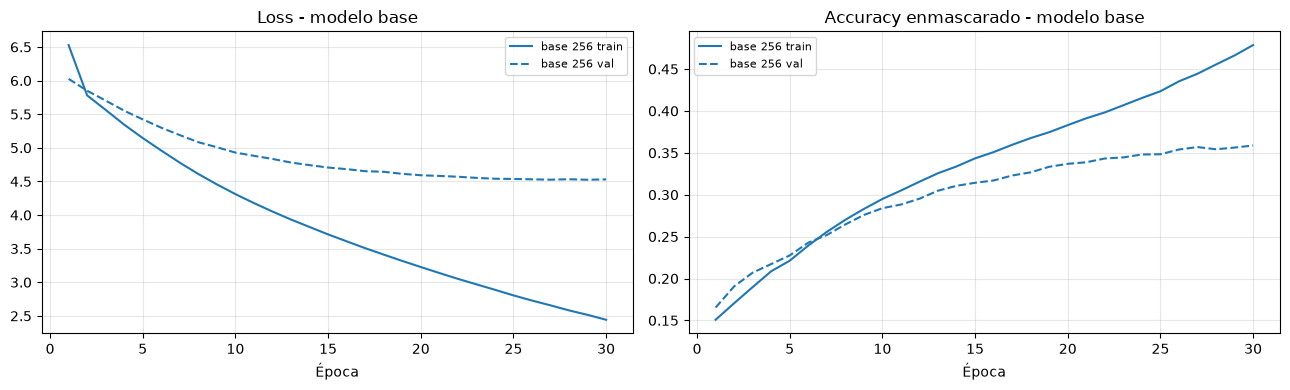

In [19]:
def plot_history(histories, title=''):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for label, h in histories.items():
        epochs = range(1, len(h['loss']) + 1)
        line, = axes[0].plot(epochs, h['loss'], label=f'{label} train')
        axes[0].plot(epochs, h['val_loss'], '--', color=line.get_color(), label=f'{label} val')
        axes[1].plot(epochs, h['accuracy'], color=line.get_color(), label=f'{label} train')
        axes[1].plot(epochs, h['val_accuracy'], '--', color=line.get_color(), label=f'{label} val')
    axes[0].set_title(f'Loss {title}');                 axes[0].set_xlabel('Época')
    axes[1].set_title(f'Accuracy enmascarado {title}'); axes[1].set_xlabel('Época')
    for ax in axes:
        ax.legend(fontsize=8); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_history({'base 256': s2s_base['history']}, '- modelo base')

Verifico que el accuracy que reporta Keras sea efectivamente el enmascarado: lo recalculo a mano sobre validación considerando solo las posiciones que no son padding, y lo comparo con el valor del historial en la mejor época (la que restaura `EarlyStopping`).

In [20]:
def masked_accuracy(s2s, split):
    pred = s2s['model'].predict([split['encoder_input'], split['decoder_input']], verbose=0).argmax(-1)
    y = split['decoder_output']
    return (pred[y > 0] == y[y > 0]).mean()


best_epoch = int(np.argmin(s2s_base['history']['val_loss']))
print(f"Accuracy de validación calculado a mano (sin padding): {masked_accuracy(s2s_base, datasets['base']['val']):.4f}")
print(f"val_accuracy de Keras en la mejor época ({best_epoch + 1}):   {s2s_base['history']['val_accuracy'][best_epoch]:.4f}")

Accuracy de validación calculado a mano (sin padding): 0.3563
val_accuracy de Keras en la mejor época (29):   0.3563


#### 4.3 - Inferencia y evaluación con BLEU

**Decodificación greedy.** En inferencia no hay *teacher forcing*: el decoder arranca con `<sos>` y en cada paso recibe como entrada **su propia predicción anterior**, eligiendo la palabra más probable (*greedy*), hasta generar `<eos>` o llegar al largo máximo. En clase esto se hacía oración por oración, con una llamada a `predict` por cada palabra; lo implemento **por lotes** (todas las oraciones avanzan un paso a la vez), lo que da exactamente el mismo resultado pero es mucho más rápido para evaluar miles de oraciones.

**BLEU.** El accuracy con *teacher forcing* no mide la calidad real de la traducción: el modelo siempre recibe las palabras correctas anteriores, y una traducción válida pero distinta de la referencia (*"Ven aquí"* vs. *"Vení acá"*) cuenta como error. Por eso evalúo con **BLEU** sobre test, la métrica estándar de traducción automática. BLEU compara los n-gramas (de 1 a 4 palabras) de la traducción generada contra los de las traducciones de referencia y penaliza las traducciones demasiado cortas. Va de 0 a 100. Como separé por oración de origen, uso **todas las traducciones de referencia** disponibles de cada oración en inglés, lo que hace la métrica más justa con traducciones alternativas válidas. Comparo sobre la misma tokenización que usa el modelo (minúsculas, sin puntuación).

In [21]:
def greedy_decode(s2s, data, enc_seqs, batch_size=512):
    w2i = data['output_tokenizer'].word_index
    sos, eos = w2i['<sos>'], w2i['<eos>']
    translations = []

    for start in range(0, len(enc_seqs), batch_size):
        batch = enc_seqs[start:start + batch_size]
        h, c = s2s['encoder'](batch, training=False)
        token = np.full((len(batch), 1), sos)
        out = np.zeros((len(batch), data['max_out_len']), dtype=int)
        done = np.zeros(len(batch), dtype=bool)

        for t in range(data['max_out_len']):
            probs, h, c = s2s['decoder']([tf.constant(token), h, c], training=False)
            probs = probs.numpy()[:, 0, :]
            probs[:, 0] = 0                       # nunca elegir el índice de padding
            next_token = probs.argmax(axis=-1)
            out[:, t] = next_token
            token = next_token[:, None]
            done |= next_token == eos
            if done.all():
                break

        translations += ids_to_words(out, data)
    return translations


def ids_to_words(out, data):
    # Convierte las secuencias de índices generadas en listas de palabras, cortando en <eos>
    i2w, eos = data['output_tokenizer'].index_word, data['output_tokenizer'].word_index['<eos>']
    translations = []
    for row in out:
        words = []
        for idx in row:
            if idx == eos:
                break
            words.append(i2w[idx])
        translations.append(words)
    return translations


def encode_en(sentences, data):
    seqs = data['input_tokenizer'].texts_to_sequences([normalize_en(s) for s in sentences])
    return pad_sequences(seqs, maxlen=data['max_input_len'], padding='post', truncating='post')


def translate(s2s, data, sentences):
    return [' '.join(w) for w in greedy_decode(s2s, data, encode_en(sentences, data))]


def tokenize_es(text):
    return text_to_word_sequence(text, filters=OUTPUT_FILTERS)


def evaluate_bleu(s2s, data, test_split):
    # data: tokenizers y largos del modelo | test_split: oraciones sobre las que se evalúa
    # Agrupo todas las traducciones de referencia de cada oración en inglés
    refs = defaultdict(list)
    for en, es in zip(test_split['en'], test_split['es']):
        refs[en].append(tokenize_es(es))
    sources = list(refs)
    hyps = greedy_decode(s2s, data, encode_en(sources, data))
    bleu = corpus_bleu([refs[s] for s in sources], hyps,
                       smoothing_function=SmoothingFunction().method1) * 100
    return bleu, sources, hyps, refs


t0 = time.time()
bleu_base, sources, hyps, refs = evaluate_bleu(s2s_base, datasets['base'], datasets['base']['test'])
print(f"BLEU (test, {len(sources)} oraciones): {bleu_base:.2f}   [{time.time() - t0:.1f} s]")

BLEU (test, 1022 oraciones): 3.21   [1.5 s]


Miro algunos ejemplos de test para tener una idea cualitativa de las traducciones del modelo base:

In [22]:
def show_examples(sources, hyps, refs, n=8, seed=SEED):
    idx = np.random.default_rng(seed).choice(len(sources), size=n, replace=False)
    for i in idx:
        print(f"EN:          {sources[i]}")
        print(f"ES (ref):    {' | '.join(' '.join(r) for r in refs[sources[i]])}")
        print(f"ES (modelo): {' '.join(hyps[i])}\n")


show_examples(sources, hyps, refs)

EN:          She can sew very well.
ES (ref):    ella sabe coser muy bien
ES (modelo): ella puede ser muy bien

EN:          I asked the man what his name was.
ES (ref):    le pregunté al hombre cómo se llamaba
ES (modelo): le pedí a la madre que era un buen amigo

EN:          The girl lent her friend her new typewriter.
ES (ref):    la chica le prestó a su amiga su nueva máquina de escribir
ES (modelo): mi padre le dio a su madre que le gusta a su madre

EN:          How can you be so calm?
ES (ref):    cómo pueden estar tan tranquilos
ES (modelo): cómo te vas a mí

EN:          We're your neighbors.
ES (ref):    somos tus vecinos
ES (modelo): estamos en contra de la escuela

EN:          Does he go to work by bus?
ES (ref):    él va al trabajo en autobús
ES (modelo): a él le gusta que la casa a la escuela

EN:          Tom eventually agreed.
ES (ref):    tom finalmente accedió
ES (modelo): tom se negó

EN:          When one has a wonderful dream, one doesn't wish to come down to ear

**Interpretación del modelo base.** Con la configuración de clase, el modelo alcanza un accuracy de validación (enmascarado) de **35,6%** y un **BLEU de 3,2** en test. En las curvas, la loss de validación se estanca alrededor de 4,5 en las últimas épocas mientras la de entrenamiento sigue bajando, y en la mejor época el accuracy de train (46,6%) supera en 11 puntos al de validación: con solo 8.000 pares, el modelo empieza a memorizar el entrenamiento en lugar de generalizar.

Los ejemplos muestran el patrón típico de este modelo: a veces acierta el comienzo de la oración (*"She can sew very well."* → *"ella puede ser muy bien"*, *"How can you be so calm?"* → *"cómo te vas a mí"*), pero después se desvía hacia fragmentos muy frecuentes del corpus (*"me gusta que..."*, *"a la escuela"*, *"su madre"*). El decoder se comporta casi como un modelo de lenguaje del español que usa muy poco la información del encoder. Es la misma calidad que se ve en el notebook de clase, y confirma que **con 10.000 oraciones el cuello de botella son los datos**.

### 5 - Modelo extendido: más datos y secuencias más largas

Entreno exactamente la misma arquitectura e hiperparámetros (`n_units = 256`, mismos callbacks y optimizador), pero con la configuración de datos **extendida**: el corpus completo, oraciones de hasta 25 palabras y un vocabulario de 10.000 palabras por idioma. Así, cualquier diferencia de desempeño se debe a los datos y no al modelo.

[extendido_256] pesos e historial cargados desde disco.


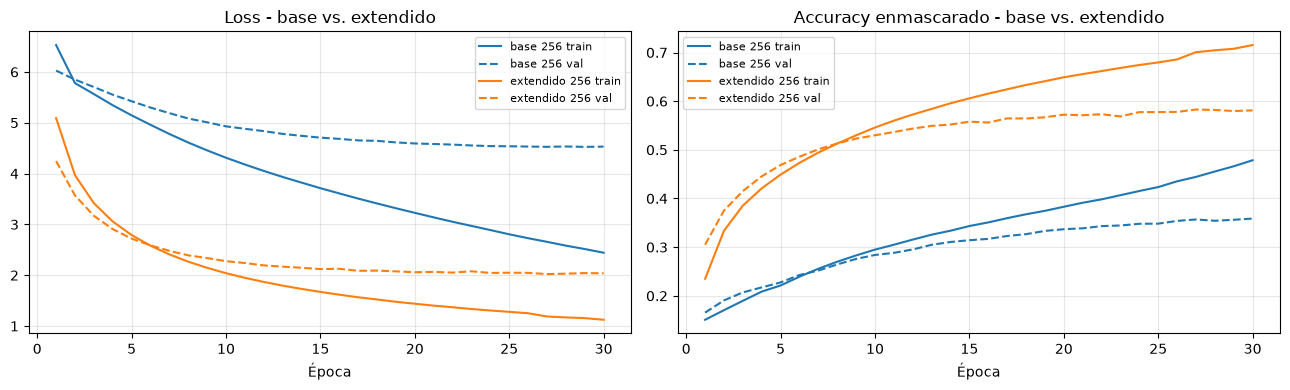

In [23]:
s2s_ext = train_or_load('extendido_256', datasets['extendido'], n_units=256)
plot_history({'base 256': s2s_base['history'], 'extendido 256': s2s_ext['history']}, '- base vs. extendido')

Para comparar ambos modelos de forma justa, los evalúo **sobre el mismo conjunto de test**: el del dataset extendido, que contiene al del base y no tiene oraciones vistas en el entrenamiento de ninguno de los dos (lo verifiqué en la sección 2). Defino una función que resume cada modelo en una fila de tabla, que reutilizo en la sección siguiente.

La `val_loss` y el `val_accuracy` **no son directamente comparables entre ambos modelos**: cada uno se mide sobre su propio conjunto de validación y con su propio vocabulario de salida (6.900 contra 10.000 palabras). BLEU sobre el test común sí es comparable.

In [24]:
TEST_COMMON = datasets['extendido']['test']
results, outputs = {}, {}


def summarize(name, s2s, data):
    h = s2s['history']
    best = int(np.argmin(h['val_loss']))
    bleu, sources, hyps, refs = evaluate_bleu(s2s, data, TEST_COMMON)
    outputs[name] = dict(sources=sources, hyps=hyps, refs=refs)
    results[name] = {
        'n_units': s2s['n_units'],
        'pares train': len(data['train']['en']),
        'parámetros': s2s['model'].count_params(),
        'épocas': len(h['loss']),
        'mejor época': best + 1,
        'val_loss': h['val_loss'][best],
        'val_acc': h['val_accuracy'][best],
        'BLEU test común': bleu,
        'seg/época': np.mean(h['epoch_time']),
    }
    return results[name]


summarize('base 256', s2s_base, datasets['base'])
summarize('extendido 256', s2s_ext, datasets['extendido'])
pd.DataFrame(results).T.round(3)

,n_units,pares train,parámetros,épocas,mejor época,val_loss,val_acc,BLEU test común,seg/época
base 256,256.0,7969.0,4606560.0,30.0,29.0,4.525,0.356,3.392,4.952
extendido 256,256.0,95353.0,6469680.0,30.0,27.0,2.023,0.583,20.337,79.625


#### Desempeño según la longitud de la oración

Para analizar específicamente el efecto de extender el entrenamiento a **secuencias más largas**, calculo BLEU por separado para distintos rangos de longitud de la oración de entrada.

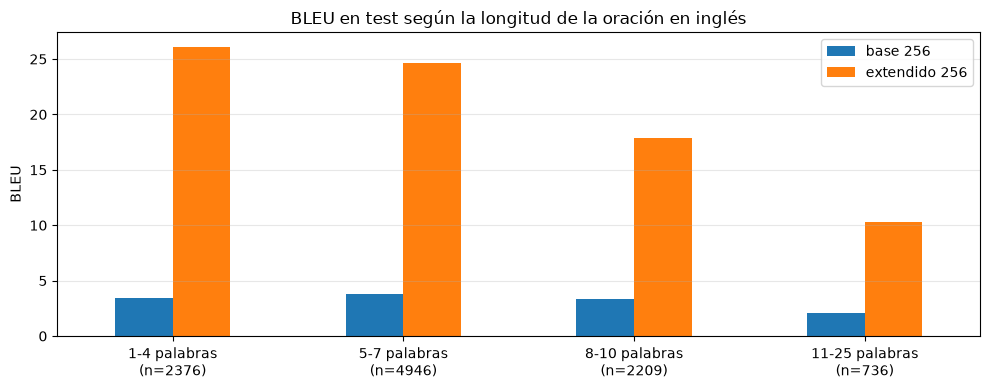

,base 256,extendido 256
1-4 palabras\n(n=2376),3.46,26.10
5-7 palabras\n(n=4946),3.79,24.61
8-10 palabras\n(n=2209),3.35,17.86
11-25 palabras\n(n=736),2.11,10.25


In [25]:
LENGTH_BINS = [(1, 4), (5, 7), (8, 10), (11, 25)]


def bleu_by_length(out, bins=LENGTH_BINS):
    res = {}
    for lo, hi in bins:
        idx = [i for i, s in enumerate(out['sources']) if lo <= len(s.split()) <= hi]
        bleu = corpus_bleu([out['refs'][out['sources'][i]] for i in idx], [out['hyps'][i] for i in idx],
                           smoothing_function=SmoothingFunction().method1) * 100
        res[f'{lo}-{hi} palabras\n(n={len(idx)})'] = bleu
    return res


def plot_bleu_by_length(model_names):
    df = pd.DataFrame({m: bleu_by_length(outputs[m]) for m in model_names})
    ax = df.plot.bar(figsize=(10, 4), rot=0)
    ax.set_ylabel('BLEU'); ax.set_title('BLEU en test según la longitud de la oración en inglés')
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()
    return df


plot_bleu_by_length(['base 256', 'extendido 256']).round(2)

Comparo las traducciones de ambos modelos sobre las mismas oraciones de test:

In [26]:
def compare_examples(model_names, n=8, seed=SEED):
    sources = outputs[model_names[0]]['sources']
    for i in np.random.default_rng(seed).choice(len(sources), size=n, replace=False):
        src = sources[i]
        print(f"EN:  {src}")
        print(f"REF: {' | '.join(' '.join(r) for r in outputs[model_names[0]]['refs'][src])}")
        width = max(len(m) for m in model_names)
        for m in model_names:
            hyp = outputs[m]['hyps'][outputs[m]['sources'].index(src)]
            print(f"  {m:{width}s} -> {' '.join(hyp)}")
        print()


compare_examples(['base 256', 'extendido 256'])

EN:  Can I have some?
REF: me dan un poco | me das un poco
  base 256      -> puedo hacer esto
  extendido 256 -> puedo hacer algo

EN:  I want something more.
REF: quiero algo más
  base 256      -> yo me gusta más
  extendido 256 -> quiero algo más

EN:  Tom doesn't have time to talk to you now.
REF: tom no tiene tiempo para hablar ahora | tom no tiene tiempo para conversar contigo ahora
  base 256      -> tom no sabe que mary no le gusta la escuela
  extendido 256 -> tom no tiene tiempo para hablar contigo ahora

EN:  Our problems are nothing compared to hers.
REF: nuestros problemas no son nada comparado a los suyos
  base 256      -> los mujeres son dos y son las árboles
  extendido 256 -> nuestros problemas no son nada comparados con los suyos

EN:  I wish I'd been born Canadian.
REF: desearía haber nacido canadiense
  base 256      -> pensé que me he visto a la cama
  extendido 256 -> desearía haber nacido canadiense

EN:  I'm responsible for Tom's safety.
REF: soy responsable d

**Interpretación.** Extender el dataset es, por lejos, el cambio con mayor impacto de todo el trabajo: con **exactamente el mismo modelo**, el BLEU en el test común pasa de **3,4 a 20,3** (unas 6 veces mayor).

* **Mejora en todas las longitudes**, incluidas las oraciones largas: en las de 11 a 25 palabras el BLEU pasa de 2,1 a 10,3. Con 12 veces más datos el modelo ve suficientes ejemplos largos como para aprender a traducirlos al menos parcialmente.
* **Pero el BLEU sigue cayendo con la longitud** (de 26 en oraciones de 1-4 palabras a 10 en las de 11-25). Esto ya no es un problema de datos sino de la arquitectura, y lo analizo en la sección siguiente.
* **Salto cualitativo**: el modelo extendido produce traducciones correctas o casi correctas (*"I wish I'd been born Canadian."* → *"desearía haber nacido canadiense"*, *"Our problems are nothing compared to hers."* → *"nuestros problemas no son nada comparados con los suyos"*), donde el base inventaba frases sin relación con el original.
* **Los errores que quedan** se concentran en palabras poco frecuentes (que el modelo traduce como `<unk>`) y en números (*"Registration starts at 2:30."* → *"el `<unk>` comienza a las 8 y media"*), tal como anticipé en las secciones 2 y 3.
* **Costo**: cada época tarda unas 16 veces más (5 s contra 80 s en la GPU de Colab), por los 12 veces más datos y por las secuencias y el vocabulario de salida más grandes.

### 6 - Impacto del número de unidades en las capas LSTM

Sobre la configuración extendida, entreno el mismo modelo variando `n_units` (el tamaño del estado oculto de **ambas** LSTM, que también es la dimensión del embedding del decoder, igual que en clase): **64, 128, 256 y 512**. El resto de los hiperparámetros queda fijo. El modelo de 256 unidades es el que ya entrené en la sección 5.

`n_units` controla la **capacidad** del modelo en dos lugares críticos:
* El **vector de contexto** `(h, c)`: toda la oración en inglés tiene que comprimirse en un vector de `n_units` valores (×2, contando el estado de celda). Con pocas unidades es esperable que el modelo "olvide" partes de las oraciones largas.
* El **decoder**, que con ese mismo estado tiene que llevar la cuenta de qué ya tradujo y qué falta.

Como contrapartida, más unidades implican más parámetros (más riesgo de sobreajuste) y más costo por época.

In [27]:
UNITS_SWEEP = [64, 128, 256, 512]
sweep = {}

for n_units in UNITS_SWEEP:
    if n_units == 256:
        sweep[n_units] = s2s_ext            # ya entrenado en la sección 5
    else:
        sweep[n_units] = train_or_load(f'extendido_{n_units}', datasets['extendido'], n_units=n_units)

[extendido_64] pesos e historial cargados desde disco.
[extendido_128] pesos e historial cargados desde disco.


[extendido_512] pesos e historial cargados desde disco.


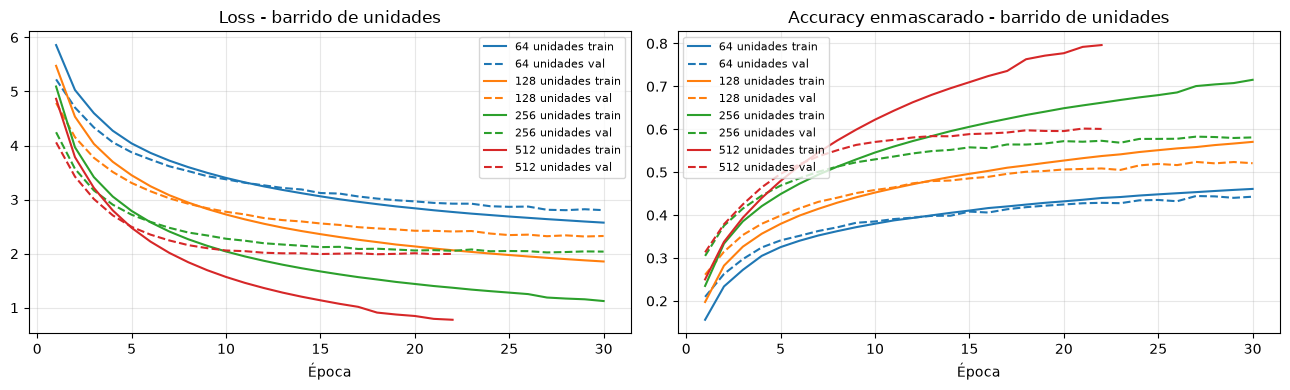

In [28]:
plot_history({f'{u} unidades': sweep[u]['history'] for u in UNITS_SWEEP}, '- barrido de unidades')

Resumo cada configuración y la evalúo sobre el test común. Agrego también la **brecha de generalización** (accuracy de train − accuracy de validación en la mejor época), como medida de sobreajuste.

In [29]:
for u in UNITS_SWEEP:
    summarize(f'extendido {u}', sweep[u], datasets['extendido'])
    best = int(np.argmin(sweep[u]['history']['val_loss']))
    results[f'extendido {u}']['brecha acc'] = (sweep[u]['history']['accuracy'][best]
                                              - sweep[u]['history']['val_accuracy'][best])

df_sweep = pd.DataFrame({f'extendido {u}': results[f'extendido {u}'] for u in UNITS_SWEEP}).T
df_sweep.round(3)

,n_units,pares train,parámetros,épocas,mejor época,val_loss,val_acc,BLEU test común,seg/época,brecha acc
extendido 64,64.0,95353.0,1852464.0,30.0,28.0,2.804,0.444,7.337,59.027,0.013
extendido 128,128.0,95353.0,3293232.0,30.0,29.0,2.318,0.524,13.493,63.396,0.043
extendido 256,256.0,95353.0,6469680.0,30.0,27.0,2.023,0.583,20.337,79.625,0.118
extendido 512,512.0,95353.0,14002224.0,22.0,18.0,1.989,0.598,21.763,120.251,0.166


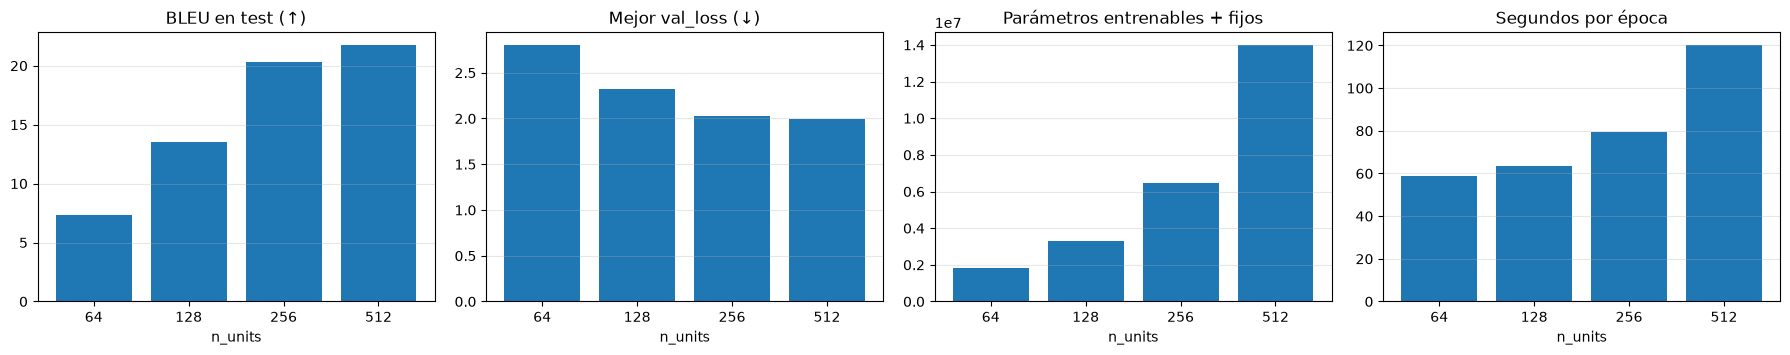

In [30]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
x = df_sweep['n_units'].astype(int).astype(str)
for ax, col, title in zip(axes,
                          ['BLEU test común', 'val_loss', 'parámetros', 'seg/época'],
                          ['BLEU en test (↑)', 'Mejor val_loss (↓)', 'Parámetros entrenables + fijos', 'Segundos por época']):
    ax.bar(x, df_sweep[col].astype(float), color=sns.color_palette()[0])
    ax.set_title(title); ax.set_xlabel('n_units'); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Y el BLEU por longitud de oración para cada configuración, para ver si más capacidad ayuda especialmente en las oraciones largas (donde el vector de contexto tiene que resumir más información):

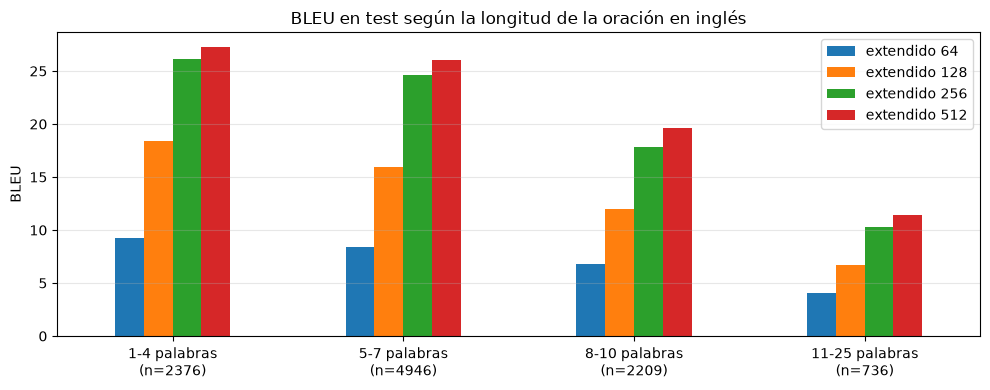

,extendido 64,extendido 128,extendido 256,extendido 512
1-4 palabras\n(n=2376),9.28,18.42,26.10,27.28
5-7 palabras\n(n=4946),8.38,15.96,24.61,26.00
8-10 palabras\n(n=2209),6.81,11.99,17.86,19.64
11-25 palabras\n(n=736),4.10,6.75,10.25,11.41


In [31]:
plot_bleu_by_length([f'extendido {u}' for u in UNITS_SWEEP]).round(2)

In [32]:
compare_examples([f'extendido {u}' for u in UNITS_SWEEP], n=5)

EN:  He can write with either hand.
REF: él puede escribir con cualquier mano
  extendido 64  -> él puede hablar con los <unk>
  extendido 128 -> él puede leer con sus palabras
  extendido 256 -> él puede hablar con más de <unk>
  extendido 512 -> él puede escribir en el <unk> y algo

EN:  Our problems are nothing compared to hers.
REF: nuestros problemas no son nada comparado a los suyos
  extendido 64  -> las cosas no son <unk> de sus cosas
  extendido 128 -> nuestros problemas no son más importantes que la vida
  extendido 256 -> nuestros problemas no son nada comparados con los suyos
  extendido 512 -> nuestros problemas no son <unk> para los <unk>

EN:  What's your favorite song on this album?
REF: cuál es tu canción favorita de este álbum
  extendido 64  -> cuál es tu nombre de esta canción favorita de la música
  extendido 128 -> cuál es tu canción favorita de la película
  extendido 256 -> cuál es tu canción favorita de esta película favorita
  extendido 512 -> cuál es tu canci

**Interpretación del barrido de unidades.**

* **Desempeño con rendimientos decrecientes.** El BLEU crece con el número de unidades (**7,3 → 13,5 → 20,3 → 21,8**), pero cada duplicación aporta menos: de 64 a 128 suma 6,2 puntos, de 128 a 256 suma 6,8, y de 256 a 512 apenas **1,4 puntos**, con más del doble de parámetros (6,5 M → 14,0 M). La mejor `val_loss` sigue la misma tendencia (2,80 → 2,32 → 2,02 → 1,99).
* **Más capacidad, más sobreajuste.** La brecha entre el accuracy de train y el de validación crece con las unidades: **1,3 → 4,3 → 11,8 → 16,6 puntos**. Los modelos de 64 y 128 unidades están en régimen de *subajuste*: su `val_loss` seguía bajando lentamente en la época 30 (la mejor fue la 28 y la 29), por lo que se beneficiarían de más épocas. El de 512, en cambio, *sobreajusta*: alcanzó su mejor `val_loss` en la época 18, el *early stopping* lo cortó en la 22, y su loss de entrenamiento (0,78) quedó muy por debajo de la de validación (~2,0). Entre 256 y 512 unidades la capacidad deja de ser el factor limitante: pasan a serlo los datos y la regularización (el modelo solo tiene dropout en los embeddings).
* **Longitud de las oraciones.** Más unidades mejoran todas las longitudes, pero la caída con la longitud persiste: incluso con 512 unidades, el BLEU en oraciones de 11 a 25 palabras (11,4) es menos de la mitad que en las de 1 a 4 (27,3). Un vector de contexto más grande alivia, pero no resuelve, el cuello de botella de **comprimir toda la oración en un único vector de tamaño fijo**.
* **Costo computacional.** El tiempo por época pasa de 59 s (64 unidades) a 120 s (512 unidades). Crece mucho menos que los parámetros (7,6 veces más), probablemente porque en GPU una parte importante del costo es fija: la softmax sobre 10.000 palabras y el recorrido secuencial de las LSTM, que no se puede paralelizar a lo largo del tiempo.
* **Cualitativamente**, con 64 unidades las traducciones son genéricas y llenas de `<unk>`, y desde 256 aparecen traducciones correctas de oraciones de 7-8 palabras. Aun así, en ejemplos individuales el modelo más grande no siempre gana (en *"Our problems are nothing compared to hers."* acierta el de 256 y no el de 512).

En resumen, el modelo de **512 unidades es el mejor en BLEU**, pero el de **256 ofrece casi el mismo desempeño con menos de la mitad de parámetros y dos tercios del tiempo de entrenamiento**. Para aprovechar mejor la capacidad del de 512 haría falta más regularización (más dropout, también en las conexiones recurrentes) o más datos.

### 7 - Ejemplos de traducción con el mejor modelo

Elijo el mejor modelo del barrido según BLEU en test y genero traducciones en tres escenarios:

1. **Oraciones de test elegidas al azar**, con su BLEU a nivel de oración. Es una métrica ruidosa para frases cortas, pero sirve de referencia.
2. **Las mejores y peores traducciones** de test (entre oraciones de al menos 5 palabras), para entender en qué casos funciona el modelo y en cuáles falla.
3. **Frases nuevas** escritas por mí, incluyendo las que se usaron en el notebook de clase, comparando con el modelo base.

In [33]:
best_name = max([f'extendido {u}' for u in UNITS_SWEEP], key=lambda m: results[m]['BLEU test común'])
best_s2s  = sweep[results[best_name]['n_units']]
best_out  = outputs[best_name]
smooth    = SmoothingFunction().method1
print(f"Mejor modelo: {best_name} (BLEU test = {results[best_name]['BLEU test común']:.2f})")

sent_bleu = np.array([sentence_bleu(best_out['refs'][s], h, smoothing_function=smooth) * 100
                      for s, h in zip(best_out['sources'], best_out['hyps'])])


def print_example(i):
    src = best_out['sources'][i]
    print(f"EN:     {src}")
    print(f"REF:    {' | '.join(' '.join(r) for r in best_out['refs'][src])}")
    print(f"MODELO: {' '.join(best_out['hyps'][i])}   (BLEU oración: {sent_bleu[i]:.1f})\n")


print("=" * 25, "Oraciones de test al azar", "=" * 25, "\n")
for i in np.random.default_rng(SEED + 1).choice(len(best_out['sources']), size=8, replace=False):
    print_example(i)

Mejor modelo: extendido 512 (BLEU test = 21.76)


========================= Oraciones de test al azar ========================= 

EN:     It was a difficult game.
REF:    fue un juego difícil
MODELO: fue una lucha justa   (BLEU oración: 8.0)

EN:     They created a government.
REF:    ellos crearon un gobierno
MODELO: ellos <unk> un arma   (BLEU oración: 9.6)

EN:     Tom has to go see Mary.
REF:    tom tiene que ir a ver a mary | tom debe ir a ver a mary
MODELO: tom tiene que ir a mary   (BLEU oración: 71.2)

EN:     Tom and Mary crashed John's party.
REF:    tom y mary irrumpieron en la fiesta de john
MODELO: tom y mary se <unk> el concierto de john   (BLEU oración: 14.9)

EN:     We have time.
REF:    tenemos tiempo
MODELO: tenemos tiempo   (BLEU oración: 31.6)

EN:     You may choose one of them.
REF:    podéis elegir uno
MODELO: puedes elegir uno y uno   (BLEU oración: 11.4)

EN:     This watch needs to be fixed.
REF:    hay que arreglar este reloj
MODELO: este reloj debe ser <unk>   (BLEU oración: 11.4)

EN:     Tom speaks slowl

In [34]:
long_enough = np.array([len(s.split()) >= 5 for s in best_out['sources']])
order = np.argsort(sent_bleu)
best_idx  = [i for i in order[::-1] if long_enough[i]][:5]
worst_idx = [i for i in order if long_enough[i]][:5]

print("=" * 25, "Mejores traducciones (>= 5 palabras)", "=" * 25, "\n")
for i in best_idx:
    print_example(i)
print("=" * 25, "Peores traducciones (>= 5 palabras)", "=" * 25, "\n")
for i in worst_idx:
    print_example(i)

========================= Mejores traducciones (>= 5 palabras) ========================= 

EN:     You'll have to wait and see.
REF:    tendrás que esperar a ver qué pasa | tendrás que esperar y ver
MODELO: tendrás que esperar a ver   (BLEU oración: 100.0)

EN:     May I pay with a credit card?
REF:    puedo pagar con tarjeta de crédito
MODELO: puedo pagar con tarjeta de crédito   (BLEU oración: 100.0)

EN:     I want to go to the store.
REF:    quiero ir a la tienda
MODELO: quiero ir a la tienda   (BLEU oración: 100.0)

EN:     Tom helped Mary wash the dishes.
REF:    tom ayudó a mary a lavar los platos
MODELO: tom ayudó a mary a lavar los platos   (BLEU oración: 100.0)

EN:     I have nothing to hide.
REF:    no tengo nada que ocultar | no tengo nada que esconder
MODELO: no tengo nada que esconder   (BLEU oración: 100.0)

========================= Peores traducciones (>= 5 palabras) ========================= 

EN:     They are making a salad.
REF:    ellos preparan una ensalada
MODEL

In [35]:
new_sentences = [
    # Frases usadas en el notebook de clase
    "My mother says hi.",
    "Where is the train station?",
    "I love learning languages.",
    "Can you help me?",
    # Frases propias, de distinta longitud y estructura
    "I don't like coffee.",
    "Tom is reading a book.",
    "We are going to the beach tomorrow.",
    "She doesn't want to go to school today.",
    "My brother and I watched a very interesting movie last night.",
]

pred_base = translate(s2s_base, datasets['base'], new_sentences)
pred_best = translate(best_s2s, datasets['extendido'], new_sentences)
for s, pb, pm in zip(new_sentences, pred_base, pred_best):
    print(f"EN:  {s}")
    print(f"  base 256       -> {pb}")
    print(f"  {best_name:14s} -> {pm}\n")

EN:  My mother says hi.
  base 256       -> mi padre me hizo a tom
  extendido 512  -> mi madre te dice

EN:  Where is the train station?
  base 256       -> dónde está en el parque
  extendido 512  -> dónde está la estación de tren

EN:  I love learning languages.
  base 256       -> me gusta la gente de café
  extendido 512  -> me encanta aprender idiomas

EN:  Can you help me?
  base 256       -> puedes ayudarme
  extendido 512  -> puedes ayudarme

EN:  I don't like coffee.
  base 256       -> no me gusta la televisión
  extendido 512  -> no me gusta el café

EN:  Tom is reading a book.
  base 256       -> tom es un buen restaurante
  extendido 512  -> tom está leyendo un libro

EN:  We are going to the beach tomorrow.
  base 256       -> estamos en ir a la escuela
  extendido 512  -> mañana vamos a ir al parque

EN:  She doesn't want to go to school today.
  base 256       -> ella no le gusta que ir a la escuela
  extendido 512  -> ella no quiere ir a la escuela hoy

EN:  My brothe

**Interpretación de los ejemplos.**

* **Frases nuevas:** el salto respecto del modelo base es claro. De las 9 frases, el modelo de 512 unidades traduce correctamente 6 (*"Where is the train station?"* → *"dónde está la estación de tren"*, *"I love learning languages."* → *"me encanta aprender idiomas"*, *"Tom is reading a book."* → *"tom está leyendo un libro"*, *"She doesn't want to go to school today."* → *"ella no quiere ir a la escuela hoy"*). Las negaciones salen bien, algo que se apoya en la expansión de contracciones de la sección 2. Falla en la expresión idiomática *"My mother says hi."* (*"mi madre te dice"*, traducción literal), cambia *beach* por *parque*, y en la oración más larga se repite y pierde el sentido (*"mi hermano y yo y yo estuvimos..."*).
* **Mejores traducciones:** oraciones cortas o medianas con vocabulario frecuente, que coinciden exactamente con alguna de las referencias (*"May I pay with a credit card?"* → *"puedo pagar con tarjeta de crédito"*, *"Tom helped Mary wash the dishes."* → *"tom ayudó a mary a lavar los platos"*).
* **BLEU por oración subestima las traducciones válidas:** *"Tom speaks slowly."* → *"tom habla despacio"* es correcta, pero obtiene 24 porque la referencia dice *"lentamente"*. Con una o dos referencias por oración, BLEU castiga los sinónimos y las paráfrasis.
* **Errores típicos:**
  1. *Palabras poco frecuentes*: el modelo genera `<unk>` o las reemplaza por una palabra frecuente de la misma categoría (*salad* → *sándwich*, *party* → *concierto*, *created* → `<unk>`).
  2. *Traducciones fluidas pero infieles*: gramaticalmente correctas pero con otro significado (*"It was a difficult game."* → *"fue una lucha justa"*, *"They are making a salad."* → *"están comiendo un sándwich"*). Son las más peligrosas, porque "suenan bien".
  3. *Oraciones largas y estructuras poco comunes*: el modelo pierde el hilo (*"Lead us, since you know the road."* → *"cuanto más te `<unk>` al ver la policía"*).

### 8 - Estrategias de generación: greedy, beam search y sampling (actividad opcional)

Hasta acá todas las traducciones se generaron con **decodificación greedy**: en cada paso el decoder elige la palabra más probable y sigue. Es rápido, pero tiene un problema: una decisión es definitiva aunque después resulte mala. Si en el primer paso la palabra más probable lleva a una continuación pobre, el modelo no puede volver atrás. En esta sección comparo, **sin reentrenar**, distintas formas de generar la traducción a partir del mismo modelo (el mejor del barrido):

* **Beam search (búsqueda por haz):** en lugar de quedarse con una sola hipótesis, mantiene en paralelo las `k` traducciones parciales más probables (el "haz") y en cada paso las extiende con todas las palabras posibles, quedándose de nuevo con las `k` mejores según su log-probabilidad acumulada. Así puede elegir una palabra que localmente no es la más probable pero que lleva a una traducción completa más probable. Con `k = 1` es exactamente greedy.
* **Sampling (muestreo aleatorio):** en cada paso **sortea** la siguiente palabra según la distribución que da el modelo, reescalada con una **temperatura** `T`: con `T < 1` la distribución se vuelve más "picuda" (más conservadora, se acerca a greedy) y con `T > 1` más plana (más diversa y arriesgada). Es la estrategia usual para generación creativa, como en el desafío 3, pero en traducción, donde hay una respuesta "correcta", es esperable que empeore la calidad.

**Normalización por longitud.** Beam search compara hipótesis por la suma de las log-probabilidades de sus palabras, y como cada palabra suma un término negativo, **favorece las traducciones cortas**, que BLEU penaliza. Para compensarlo, al elegir la hipótesis final divido el score por `largo^α`. Con `α = 0` no hay normalización y con `α = 1` es el promedio por palabra. Comparo ambas variantes.

In [36]:
def beam_search_decode(s2s, data, enc_seqs, beam_width=5, alpha=0.7, batch_size=128):
    w2i = data['output_tokenizer'].word_index
    sos, eos = w2i['<sos>'], w2i['<eos>']
    V, L, k = data['num_words_output'], data['max_out_len'], beam_width
    translations = []

    for start in range(0, len(enc_seqs), batch_size):
        batch = enc_seqs[start:start + batch_size]
        B = len(batch)
        h, c = s2s['encoder'](batch, training=False)
        h, c = tf.repeat(h, k, axis=0), tf.repeat(c, k, axis=0)      # k copias del estado por oración

        scores = np.full((B, k), -np.inf)
        scores[:, 0] = 0.0                    # al inicio solo un haz "vivo" (evita k hipótesis idénticas)
        seqs = np.zeros((B, k, L), dtype=int)
        lengths = np.zeros((B, k), dtype=int)
        finished = np.zeros((B, k), dtype=bool)
        token = np.full((B * k, 1), sos)

        for t in range(L):
            probs, h, c = s2s['decoder']([tf.constant(token), h, c], training=False)
            logp = np.log(probs.numpy()[:, 0, :] + 1e-12).reshape(B, k, V)
            logp[:, :, 0] = -np.inf                       # nunca elegir el índice de padding
            # Los haces que ya generaron <eos> solo pueden "continuar" con <eos> sin costo: conservan su score
            logp[finished] = -np.inf
            logp[finished, eos] = 0.0

            cand = (scores[:, :, None] + logp).reshape(B, k * V)       # todas las extensiones posibles
            top = np.argpartition(-cand, k - 1, axis=1)[:, :k]         # las k mejores de cada oración
            scores = np.take_along_axis(cand, top, axis=1)
            beam_idx, tok = top // V, top % V                          # de qué haz vienen y qué palabra agregan

            seqs = np.take_along_axis(seqs, beam_idx[:, :, None], axis=1)
            lengths = np.take_along_axis(lengths, beam_idx, axis=1)
            prev_finished = np.take_along_axis(finished, beam_idx, axis=1)
            seqs[:, :, t] = np.where(prev_finished, 0, tok)
            lengths += ~prev_finished
            finished = prev_finished | (tok == eos)

            flat_idx = (np.arange(B)[:, None] * k + beam_idx).ravel()  # reordeno los estados según el haz de origen
            h, c = tf.gather(h, flat_idx), tf.gather(c, flat_idx)
            token = tok.reshape(-1, 1)
            if finished.all():
                break

        final = scores / np.maximum(lengths, 1) ** alpha               # normalización por longitud
        best = final.argmax(axis=1)
        translations += ids_to_words(seqs[np.arange(B), best], data)
    return translations


def sampling_decode(s2s, data, enc_seqs, temperature=1.0, seed=SEED, batch_size=512):
    rng = np.random.default_rng(seed)
    w2i = data['output_tokenizer'].word_index
    sos, eos = w2i['<sos>'], w2i['<eos>']
    translations = []

    for start in range(0, len(enc_seqs), batch_size):
        batch = enc_seqs[start:start + batch_size]
        h, c = s2s['encoder'](batch, training=False)
        token = np.full((len(batch), 1), sos)
        out = np.zeros((len(batch), data['max_out_len']), dtype=int)
        done = np.zeros(len(batch), dtype=bool)

        for t in range(data['max_out_len']):
            probs, h, c = s2s['decoder']([tf.constant(token), h, c], training=False)
            probs = probs.numpy()[:, 0, :].astype(np.float64)
            probs[:, 0] = 0
            # Reescalar con temperatura: softmax(logits / T) es equivalente a p^(1/T) renormalizado
            probs = probs ** (1.0 / temperature)
            probs /= probs.sum(axis=1, keepdims=True)
            # Muestreo vectorizado por inversa de la distribución acumulada
            u = rng.random((len(batch), 1))
            next_token = np.minimum((probs.cumsum(axis=1) < u).sum(axis=1), probs.shape[1] - 1)
            out[:, t] = next_token
            token = next_token[:, None]
            done |= next_token == eos
            if done.all():
                break

        translations += ids_to_words(out, data)
    return translations

Verifico la implementación con un caso límite: beam search con `k = 1` tiene que dar **exactamente** las mismas traducciones que greedy.

In [37]:
ext = datasets['extendido']
test_sources, test_refs = best_out['sources'], best_out['refs']
enc_test = encode_en(test_sources, ext)

check = beam_search_decode(best_s2s, ext, enc_test[:500], beam_width=1, alpha=0)
print("Beam search (k=1) idéntico a greedy:", check == best_out['hyps'][:500])

Beam search (k=1) idéntico a greedy: True


#### 8.1 - Comparación sobre el conjunto de test

Evalúo cada estrategia sobre el test común completo con el mejor modelo. Además del BLEU, reporto el **largo medio** de las traducciones generadas en relación con el largo medio de las referencias (una relación menor a 1 indica traducciones más cortas que las reales, que BLEU penaliza) y el tiempo de decodificación.

In [38]:
def evaluate_strategy(name, decode_fn, **kwargs):
    t0 = time.time()
    hyps = decode_fn(best_s2s, ext, enc_test, **kwargs)
    elapsed = time.time() - t0
    bleu = corpus_bleu([test_refs[s] for s in test_sources], hyps, smoothing_function=smooth) * 100
    ref_len = np.mean([np.mean([len(r) for r in test_refs[s]]) for s in test_sources])
    outputs[f'{best_name} | {name}'] = dict(sources=test_sources, hyps=hyps, refs=test_refs)
    return {'BLEU test común': bleu, 'largo hip. / largo ref.': np.mean([len(h) for h in hyps]) / ref_len,
            'tiempo (s)': elapsed}


strategies = {
    'greedy':                     (beam_search_decode, dict(beam_width=1, alpha=0)),
    'beam k=3 (α=0.7)':           (beam_search_decode, dict(beam_width=3, alpha=0.7)),
    'beam k=5 (α=0.7)':           (beam_search_decode, dict(beam_width=5, alpha=0.7)),
    'beam k=10 (α=0.7)':          (beam_search_decode, dict(beam_width=10, alpha=0.7)),
    'beam k=5 (sin normalizar)':  (beam_search_decode, dict(beam_width=5, alpha=0)),
    'beam k=5 (α=1)':             (beam_search_decode, dict(beam_width=5, alpha=1.0)),
    'sampling T=0.3':             (sampling_decode, dict(temperature=0.3)),
    'sampling T=0.7':             (sampling_decode, dict(temperature=0.7)),
    'sampling T=1.0':             (sampling_decode, dict(temperature=1.0)),
    'sampling T=1.5':             (sampling_decode, dict(temperature=1.5)),
}
decoding_results = {name: evaluate_strategy(name, fn, **kw) for name, (fn, kw) in strategies.items()}
df_decoding = pd.DataFrame(decoding_results).T
df_decoding.round(3)

,BLEU test común,largo hip. / largo ref.,tiempo (s)
greedy,21.763,1.042,73.539
beam k=3 (α=0.7),24.765,1.022,151.464
beam k=5 (α=0.7),25.062,1.019,242.055
beam k=10 (α=0.7),25.309,1.017,467.198
beam k=5 (sin normalizar),25.334,0.969,234.446
beam k=5 (α=1),24.269,1.051,231.841
sampling T=0.3,21.184,1.042,74.098
sampling T=0.7,16.967,1.056,77.001
sampling T=1.0,12.483,1.067,54.814
sampling T=1.5,5.110,1.081,73.005


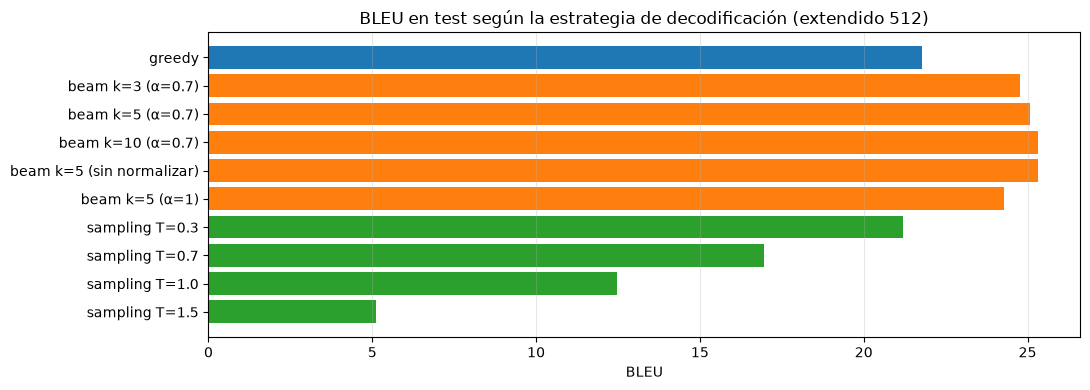

In [39]:
fig, ax = plt.subplots(figsize=(11, 4))
colors = [sns.color_palette()[0] if n.startswith('greedy') else
          sns.color_palette()[1] if n.startswith('beam') else sns.color_palette()[2] for n in df_decoding.index]
ax.barh(df_decoding.index[::-1], df_decoding['BLEU test común'][::-1], color=colors[::-1])
ax.set_xlabel('BLEU'); ax.set_title(f'BLEU en test según la estrategia de decodificación ({best_name})')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

BLEU por longitud de la oración, comparando greedy con la mejor variante de beam search y con sampling:

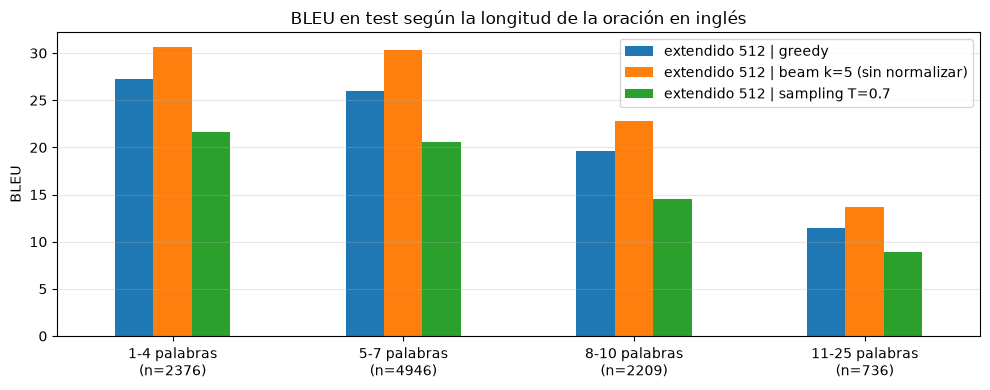

,extendido 512 | greedy,extendido 512 | beam k=5 (sin normalizar),extendido 512 | sampling T=0.7
1-4 palabras\n(n=2376),27.28,30.67,21.61
5-7 palabras\n(n=4946),26.00,30.33,20.62
8-10 palabras\n(n=2209),19.64,22.77,14.56
11-25 palabras\n(n=736),11.41,13.67,8.92


In [40]:
best_beam = df_decoding.filter(like='beam', axis=0)['BLEU test común'].idxmax()
plot_bleu_by_length([f'{best_name} | greedy', f'{best_name} | {best_beam}', f'{best_name} | sampling T=0.7']).round(2)

#### 8.2 - Ejemplos

Comparo las traducciones de las distintas estrategias sobre las mismas oraciones de test y sobre las frases nuevas de la sección 7:

In [41]:
compare_examples([f'{best_name} | greedy', f'{best_name} | {best_beam}',
                  f'{best_name} | sampling T=0.7', f'{best_name} | sampling T=1.5'], n=6, seed=SEED + 2)

EN:  He's already a man.
REF: él ya es un hombre
  extendido 512 | greedy                    -> él es un hombre enfermo
  extendido 512 | beam k=5 (sin normalizar) -> él ya es un hombre
  extendido 512 | sampling T=0.7            -> él ya está un hombre
  extendido 512 | sampling T=1.5            -> aún va bajo un estudiante

EN:  Many flights were canceled because of the typhoon.
REF: muchos vuelos fueron cancelados a causa del tifón
  extendido 512 | greedy                    -> varios pasajeros hubo escasez de guerra durante varias veces
  extendido 512 | beam k=5 (sin normalizar) -> muchos pasajeros murieron durante el terremoto
  extendido 512 | sampling T=0.7            -> muchas vuelos fueron <unk> al <unk> del terremoto
  extendido 512 | sampling T=1.5            -> varios dieciocho hubo prohibido vivir en total

EN:  Time flies like an arrow.
REF: el tiempo vuela como una flecha
  extendido 512 | greedy                    -> el tiempo vuela como un pájaro
  extendido 512 | bea

In [42]:
enc_new = encode_en(new_sentences, ext)
new_preds = {
    'greedy':        beam_search_decode(best_s2s, ext, enc_new, beam_width=1, alpha=0),
    best_beam:       beam_search_decode(best_s2s, ext, enc_new, **strategies[best_beam][1]),
    'sampling T=0.7': sampling_decode(best_s2s, ext, enc_new, temperature=0.7),
}
for i, s in enumerate(new_sentences):
    print(f"EN:  {s}")
    for name, preds in new_preds.items():
        print(f"  {name:20s} -> {' '.join(preds[i])}")
    print()

EN:  My mother says hi.
  greedy               -> mi madre te dice
  beam k=5 (sin normalizar) -> mi madre te dice
  sampling T=0.7       -> mi madre quiere decir

EN:  Where is the train station?
  greedy               -> dónde está la estación de tren
  beam k=5 (sin normalizar) -> dónde está la estación de tren
  sampling T=0.7       -> dónde está la estación de tren

EN:  I love learning languages.
  greedy               -> me encanta aprender idiomas
  beam k=5 (sin normalizar) -> me encanta aprender idiomas
  sampling T=0.7       -> me encanta aprender idiomas

EN:  Can you help me?
  greedy               -> puedes ayudarme
  beam k=5 (sin normalizar) -> puedes ayudarme
  sampling T=0.7       -> me puedes ayudar

EN:  I don't like coffee.
  greedy               -> no me gusta el café
  beam k=5 (sin normalizar) -> no me gusta el café
  sampling T=0.7       -> no me gusta el café

EN:  Tom is reading a book.
  greedy               -> tom está leyendo un libro
  beam k=5 (sin norma

Por último, muestro la **diversidad** que introduce el sampling: genero 5 traducciones de una misma oración con distintas semillas, para cada temperatura.

In [43]:
sentence = ["I don't want to go to school tomorrow."]
enc_s = encode_en(sentence, ext)
print(f"EN: {sentence[0]}\n")
for T in [0.3, 0.7, 1.0, 1.5]:
    print(f"T = {T}")
    for seed in range(5):
        print("   ", ' '.join(sampling_decode(best_s2s, ext, enc_s, temperature=T, seed=seed)[0]))
    print()

EN: I don't want to go to school tomorrow.

T = 0.3
    no quiero ir a la escuela mañana


    no quiero ir a la escuela mañana
    no quiero ir a la escuela mañana


    no quiero ir a la escuela mañana
    no quiero ir a la escuela mañana

T = 0.7


    no quiero ir a la escuela mañana
    no quiero ir al colegio mañana


    no quiero ir a la escuela mañana
    no quiero ir a la escuela mañana


...

    no quiero ir al colegio mañana
    no quiero ir a la escuela los días


    no quiero ir a la escuela mañana
    no quiero irme a la escuela mañana

T = 1.5


    no quiero ir a estados unidos mañana
    no deseo ir fuera a casa todavía


    no quiero irme a la escuela los escuela
    no quiero canadiense mañana a la escuela


    hoy no deseo ir a la escuela



**Interpretación.**

* **Beam search mejora de forma consistente, sin reentrenar.** El BLEU pasa de **21,8 con greedy a 24,8 con k = 3 y a 25,3 con k = 5-10**: unos +3,5 puntos, más de lo que se gana al duplicar las unidades de 256 a 512 (+1,4). Casi toda la ganancia aparece con k = 3; agrandar el haz da mejoras marginales (24,8 → 25,1 → 25,3), mientras que el tiempo de decodificación crece aproximadamente en proporción a k (con k = 10 tarda unas 6 veces más que greedy).
* **La mejora se da en todas las longitudes** (en las oraciones de 11 a 25 palabras, de 11,4 a 13,7), y los ejemplos muestran el mecanismo:
  * En *"He's already a man."*, greedy arranca con *"él es"* y queda atado a una continuación peor (*"él es un hombre enfermo"*), mientras que beam search encuentra *"él ya es un hombre"*.
  * En la frase larga, beam search evita la repetición *"y yo y yo"* (*"mi hermano y yo compartimos un buen cine anoche"*), y en *"We are going to the beach tomorrow."* encuentra *"mañana iremos a la playa"*.
  * En cambio, en *"Time flies like an arrow."* ambas estrategias generan *"como un pájaro"*: beam search corrige **errores de búsqueda** (el modelo asignaba más probabilidad a la traducción correcta, pero greedy no la encontraba), no **errores del modelo**.
* **La normalización por longitud no fue necesaria**, contra lo que esperaba. Sin normalizar (α = 0) se obtiene el mejor BLEU (25,3), con α = 0,7 prácticamente lo mismo, y con α = 1 empeora (24,3). La explicación está en la columna de largos: greedy ya genera traducciones algo *más largas* que las referencias (relación 1,04, en parte por repeticiones), así que favorecer las hipótesis largas (α = 1, relación 1,05) agrega palabras de más que bajan la precisión de n-gramas. Sin normalizar, el largo queda apenas por debajo de las referencias (0,97) y la penalización por brevedad de BLEU es pequeña. La diferencia entre α = 0 y α = 0,7 (≈ 0,3 puntos) es demasiado chica para sacar conclusiones.
* **El sampling empeora a medida que sube la temperatura**: con T = 0,3 se comporta casi como greedy (21,2), con T = 0,7 cae a 17,0, con T = 1 a 12,5 y con T = 1,5 a 5,1. Una sola palabra improbable al principio arrastra el resto de la oración (*"Time flies like an arrow."* → *"por neblina casi mantequilla..."*). La demostración de diversidad lo deja claro: con T ≤ 0,7 las variantes son paráfrasis válidas (*"a la escuela"* / *"al colegio"*), y con T = 1,5 se pierde el sentido.

En traducción, donde se busca la salida más fiel y no la más variada, conviene una estrategia de **búsqueda** (beam search) y no de **muestreo**. El sampling con temperatura baja podría servir, en todo caso, para generar traducciones alternativas.

### 9 - Conclusiones

#### Resumen de resultados (BLEU sobre el test común, ~10.000 oraciones)

| Configuración | Pares de entrenamiento | Parámetros | BLEU |
|---|---|---|---|
| Base (réplica de clase), 256 unidades, greedy | 7.969 | 4,6 M | 3,4 |
| Extendido, 64 unidades, greedy | 95.353 | 1,9 M | 7,3 |
| Extendido, 128 unidades, greedy | 95.353 | 3,3 M | 13,5 |
| Extendido, 256 unidades, greedy | 95.353 | 6,5 M | 20,3 |
| Extendido, 512 unidades, greedy | 95.353 | 14,0 M | 21,8 |
| **Extendido, 512 unidades, beam search (k = 5)** | 95.353 | 14,0 M | **25,3** |

#### Qué aprendí de cada experimento

1. **Más datos fue lo más importante.** Pasar de 10.000 oraciones al corpus completo, con la misma arquitectura, multiplicó el BLEU por 6 (de 3,4 a 20,3), redujo a la mitad las palabras desconocidas y mejoró todas las longitudes de oración. El modelo de clase no estaba limitado por su arquitectura ni por la longitud máxima de las secuencias, sino por la cantidad de ejemplos.
2. **El número de unidades tiene rendimientos decrecientes.** Hasta 256 unidades el BLEU crece mucho, y de 256 a 512 apenas 1,4 puntos con el doble de parámetros, mientras la brecha de sobreajuste pasa de 12 a 17 puntos. Los modelos chicos subajustan y el grande sobreajusta: el punto de equilibrio para estos datos está entre 256 y 512 unidades.
3. **La estrategia de generación importa tanto como el modelo.** Beam search sumó 3,5 puntos de BLEU sin reentrenar nada, más que duplicar la capacidad del modelo. El sampling, útil en generación creativa, empeora la traducción.
4. **Las correcciones al código de clase fueron necesarias para extender el entrenamiento.** Varios detalles que no afectaban con 10.000 oraciones se vuelven problemas al escalar o al cambiar de entorno: el token `<sos>` quedaba fuera del vocabulario, la matriz de embeddings tenía una fila de menos, el padding inflaba el accuracy (~70% de las posiciones de salida son padding) y las contracciones del inglés no tenían vector GloVe, con lo que se perdía, entre otras cosas, la negación.

#### Sobre las métricas

* **El accuracy sin máscara es engañoso**: con ~70% de padding en la salida, un modelo que solo predice padding obtiene ~70% de accuracy. Por eso el modelo de clase arranca con 65% en la primera época aun traduciendo mal.
* **El accuracy enmascarado mide predicción con *teacher forcing***: el modelo conoce las palabras correctas anteriores, algo que no ocurre al traducir. Sirve para seguir el entrenamiento, pero no mide la calidad de la traducción.
* **BLEU es más representativo, pero tiene límites**: penaliza sinónimos y paráfrasis válidas (*"despacio"* contra *"lentamente"*), y es ruidoso a nivel de oración. Además, lo calculé sobre texto en minúsculas y sin puntuación, con la tokenización del modelo, así que los valores **no son comparables** con los BLEU publicados en la literatura. Sí son comparables entre los modelos de este notebook, porque todos se evaluaron sobre el mismo test y con el mismo procedimiento.